# $\log(3/2)$: historical CMF bound

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    huttner_logs, huttner_logs_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, y0 = sp.symbols('x0 x1 y0')
target = lambda: (arb(3)/2).log()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Alladi–Robinson (1980): $\log(3/2)$

[Integral construction and measure formula](https://www.math.ru.nl/~wzudilin/gat/oALLADI4.txt).


$$E_n=\int_0^1\frac{t^n(1-t)^n}{(t+2)^{n+1}}\,dt.$$
**CMF:** rank 2, `${}_2F_1(-1/2)` · **Start:** $(2,2;4)$ · **Direction:** $(1,1;2)$.
The readout is $E_n=C_n+B_n\log(3/2)$, $p_n/q_n=-C_n/B_n$. Depth $N$ means the integral index $n=N$.
The beta-integral normalization is common to both coefficient rows and cancels in the readout; the code uses the $(F,\theta F)$ basis.

In [5]:
cmf = pFq(2, 1, -sp.Rational(1, 2))
start = {x0: 2, x1: 2, y0: 4}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
C = Matrix([[-6, 17]])
B = Matrix([[15, -42]])
approximants = [-(C * M)[0] / (B * M)[0] for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Alladi–Robinson (1980)'] = (DEPTHS, deltas)
accuracy['Alladi–Robinson (1980)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.403919676842


## 2. Huttner (2003): simultaneous logarithmic construction

[Corollary 3.1(4), pp. 146–147](https://www.jstage.jst.go.jp/article/kyushujm/57/1/57_1_129/_pdf).

**CMF:** rank-3 moments of $(z-1)^u(z-2/3)^v(z-1/2)^w z^{-m}$.
**Start/direction:** $(2,2,2,3)$. Source index N uses N−1 steps.
**Readout:** $(PW)_0/(QW)_0$ from the source's simultaneous logarithmic coefficient rows.

In [7]:
u, v, w, m = sp.symbols('u v w m')
cmf = huttner_logs()
start = {u: 2, v: 2, w: 2, m: 3}
trajectory = {u: 2, v: 2, w: 2, m: 3}
P, Q = huttner_logs_seeds(sp.Rational(3, 2))
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Huttner (2003), simultaneous'] = (DEPTHS, deltas)
accuracy['Huttner (2003), simultaneous'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.103713405071


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

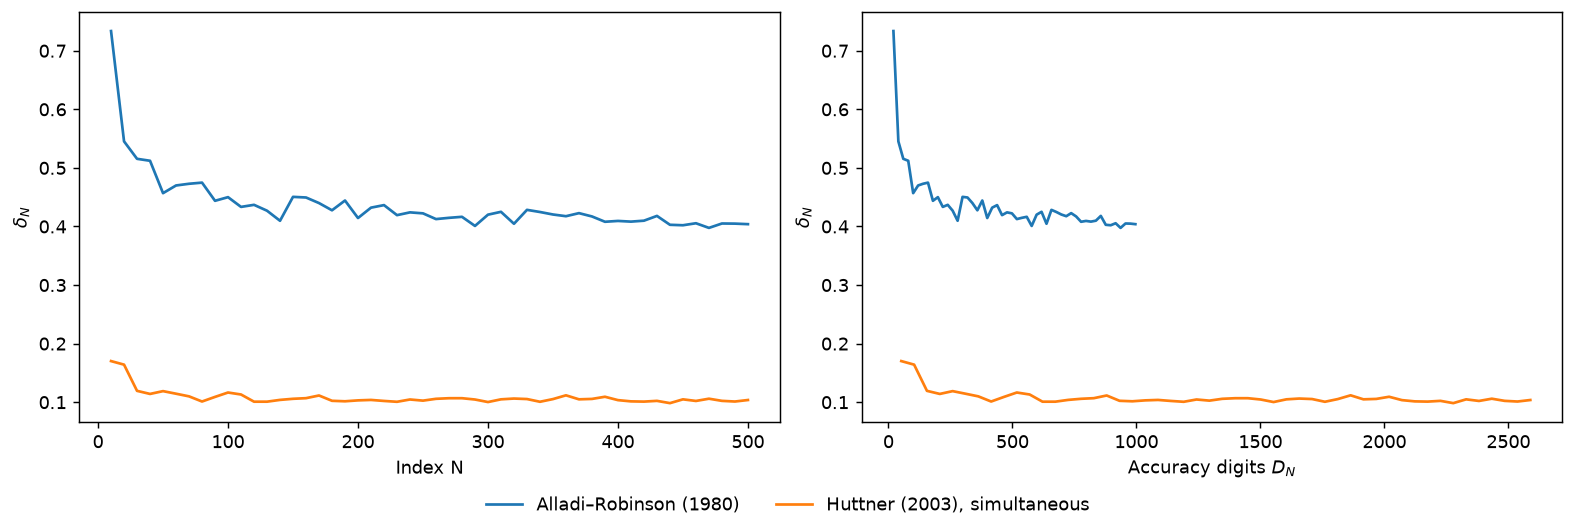

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [11]:
bounds = {
    'Alladi–Robinson (1980)': '3.547470591',
    'Huttner (2003), simultaneous': '$11.1017577\\ldots$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Alladi–Robinson (1980) | 3.547470591 | 0.403919676842 (N = 500) |
| Huttner (2003), simultaneous | $11.1017577\ldots$ | 0.103713405071 (N = 500) |